# Part 2: Classification and Model Improvement
Kidney CT Image Classification
Objective: To conduct exploratory data analysis, prepare a medical image dataset, train a classification model, evaluate its performance, and investigate possible model improvements.

Dataset: CT Kidney Dataset — Normal, Cyst, Tumor, and Stone.

Source: https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone

In [2]:
# Step 1: Import the libraries required for our analysis

# Handle numerical data and arrays
import numpy as np

# Organise and analyse data
import pandas as pd

# Create graphs and visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Work with folders and file paths
import os

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Evaluate classification performance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display plots inside the notebook
%matplotlib inline

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [3]:

# Step 2: Inspect the kidney CT dataset folders

# Set the path to the extracted dataset
dataset_path = r"C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"

# Check whether the folder exists
if os.path.exists(dataset_path):
    print("Dataset folder found successfully!")
else:
    print("Dataset folder not found. Check the path.")

# Display the contents of the dataset folder
print("\nContents of the dataset folder:")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print("Folder:", item)
    else:
        print("File:", item)


Dataset folder found successfully!

Contents of the dataset folder:
Folder: CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone


In [4]:
# Step 3: Open the inner dataset folder

# Path to the outer dataset folder
outer_path = r"C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"

# Path to the actual image dataset
dataset_path = os.path.join(
    outer_path,
    "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
)

# Check that the inner folder exists
print("Dataset folder exists:", os.path.exists(dataset_path))

# Display the contents of the inner folder
print("\nItems inside the dataset folder:")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print("Folder:", item)
    else:
        print("File:", item)

Dataset folder exists: True

Items inside the dataset folder:
Folder: Cyst
Folder: Normal
Folder: Stone
Folder: Tumor


In [6]:

# Step 3: Count images in each class

# These are the four folders we found in the dataset
classes = ["Cyst", "Normal", "Stone", "Tumor"]

# Create an empty dictionary to store the image counts
image_counts = {}

# Common image file extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# Count the images in each class folder
for class_name in classes:

    # Build the path to the current class folder
    class_path = os.path.join(dataset_path, class_name)

    # Count image files, including images in subfolders
    count = 0

    for root, folders, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                count += 1

    # Save the count
    image_counts[class_name] = count

# Display the results
print("Number of images in each class:\n")

for class_name, count in image_counts.items():
    print(f"{class_name}: {count}")

# Calculate and display the total number of images
total_images = sum(image_counts.values())

print("\nTotal number of images:", total_images)

Number of images in each class:

Cyst: 3709
Normal: 5077
Stone: 1377
Tumor: 2283

Total number of images: 12446


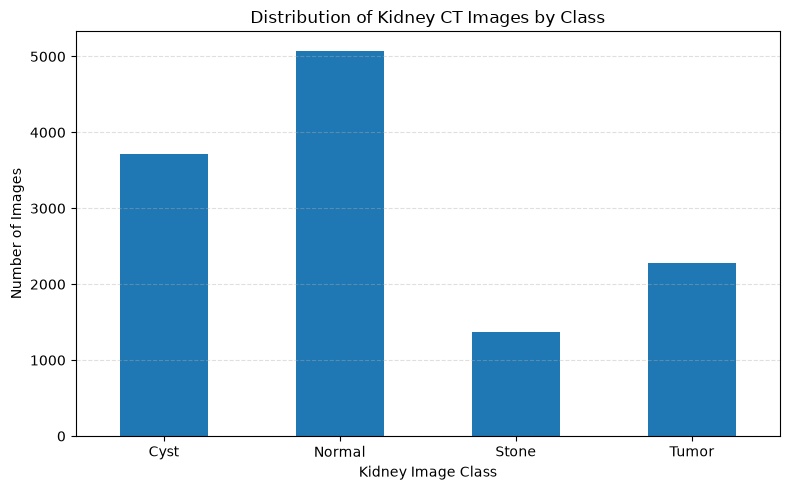

Percentage distribution of images:

Cyst: 29.80%
Normal: 40.79%
Stone: 11.06%
Tumor: 18.34%


In [7]:
# Step 4 : Visualise the number of images in each class

# Convert the image counts into a pandas Series
class_counts = pd.Series(image_counts)

# Create a bar chart
plt.figure(figsize=(8, 5))

class_counts.plot(kind="bar")

# Add a title and axis labels
plt.title("Distribution of Kidney CT Images by Class")
plt.xlabel("Kidney Image Class")
plt.ylabel("Number of Images")

# Display the class names horizontally
plt.xticks(rotation=0)

# Add a grid to make the counts easier to compare
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display the chart
plt.tight_layout()
plt.show()

# Display the percentage of images in each class
print("Percentage distribution of images:\n")

class_percentages = (class_counts / total_images) * 100

for class_name, percentage in class_percentages.items():
    print(f"{class_name}: {percentage:.2f}%")

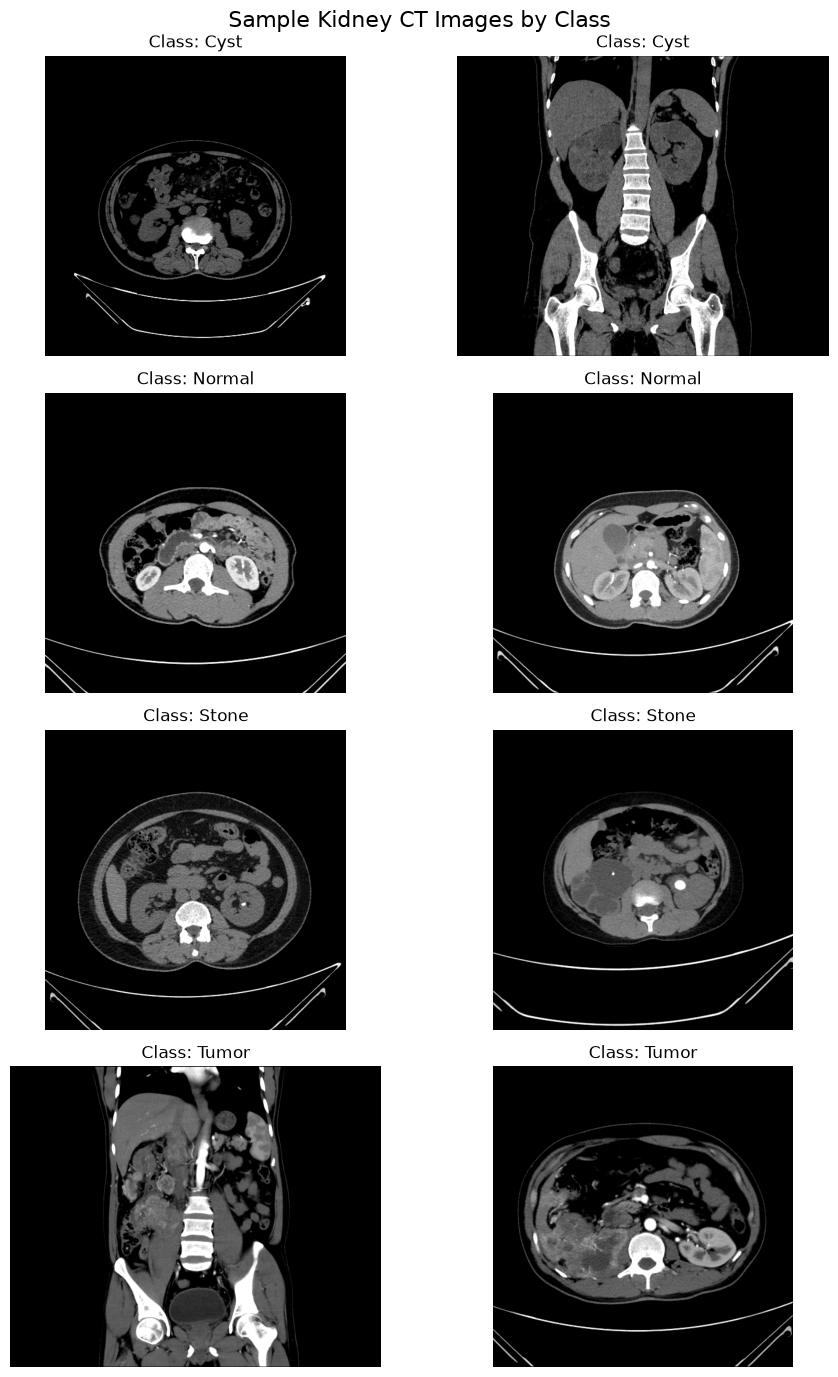

In [8]:

# Step 5: Display sample CT images from each class

from PIL import Image
import random

# Make the results reproducible
random.seed(42)

# Create a figure with 4 rows and 2 columns
fig, axes = plt.subplots(4, 2, figsize=(10, 14))

# Image file extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# Display two images from each class
for row, class_name in enumerate(classes):

    class_path = os.path.join(dataset_path, class_name)

    # Find image files in this class folder and its subfolders
    image_paths = []

    for root, folders, files in os.walk(class_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                image_paths.append(os.path.join(root, file))

    # Randomly select up to two images
    selected_images = random.sample(
        image_paths,
        min(2, len(image_paths))
    )

    for col in range(2):
        ax = axes[row, col]

        if col < len(selected_images):
            # Open the image and convert it to RGB
            img = Image.open(selected_images[col]).convert("RGB")

            # Display the image
            ax.imshow(img)
            ax.set_title(f"Class: {class_name}")
        else:
            ax.set_title(f"No image available: {class_name}")

        ax.axis("off")

# Add a heading to the figure
plt.suptitle("Sample Kidney CT Images by Class", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:

# Step 6: Create a list of image paths and labels

# Import the tools needed to work with image files
from PIL import Image
import os

# Store the image file paths and their class labels
image_paths = []
labels = []

# Supported image file extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# Go through each class folder
for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    # Find image files in this class folder and any subfolders
    for root, folders, files in os.walk(class_path):

        for file in files:

            if file.lower().endswith(image_extensions):

                # Save the full image path
                full_path = os.path.join(root, file)
                image_paths.append(full_path)

                # Save the correct class label
                labels.append(class_name)

# Convert the lists to a DataFrame
image_data = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

# Display the first five rows
print("First five image records:")
display(image_data.head())

# Display the number of records collected
print("\nTotal image records:", len(image_data))

# Check the number of images collected for each class
print("\nImages collected per class:")
print(image_data["label"].value_counts())

First five image records:


,image_path,label
0,C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Nor...,Cyst
1,C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Nor...,Cyst
2,C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Nor...,Cyst
3,C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Nor...,Cyst
4,C:\Users\dovha\Downloads\CT-KIDNEY-DATASET-Nor...,Cyst



Total image records: 12446

Images collected per class:
label
Normal    5077
Cyst      3709
Tumor     2283
Stone     1377
Name: count, dtype: int64


In [10]:
# Step 7: Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

# Use the image paths as inputs and the class names as labels
X = image_data["image_path"]
y = image_data["label"]

# Split the data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the two sets
print("Total images:", len(image_data))
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

# Check the training class distribution
print("\nTraining class distribution:")
print(y_train.value_counts())

# Check the testing class distribution
print("\nTesting class distribution:")
print(y_test.value_counts())


Total images: 12446
Training images: 9956
Testing images: 2490

Training class distribution:
label
Normal    4061
Cyst      2967
Tumor     1826
Stone     1102
Name: count, dtype: int64

Testing class distribution:
label
Normal    1016
Cyst       742
Tumor      457
Stone      275
Name: count, dtype: int64


Image array shape: (32, 32)
Minimum pixel value: 0.0
Maximum pixel value: 0.8235294


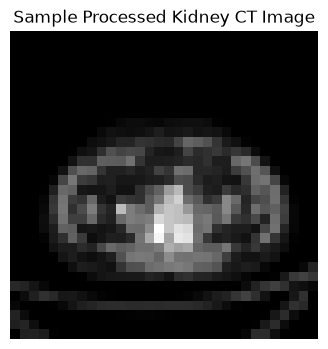

In [11]:
# Step 8: Convert images into numerical arrays

from PIL import Image
import numpy as np

# Define the image size
IMAGE_SIZE = (32, 32)

def process_image(image_path):
    """
    Open an image, convert it to grayscale,
    resize it to 32 x 32 pixels, and scale
    pixel values between 0 and 1.
    """

    # Open the image safely
    with Image.open(image_path) as img:

        # Convert to grayscale and resize
        img = img.convert("L").resize(IMAGE_SIZE)

        # Convert pixels into a NumPy array
        image_array = np.array(img, dtype=np.float32)

        # Scale pixel values from 0-255 to 0-1
        image_array = image_array / 255.0

    return image_array

# Test the function on one training image
sample_image = process_image(X_train.iloc[0])

# Display the results
print("Image array shape:", sample_image.shape)
print("Minimum pixel value:", sample_image.min())
print("Maximum pixel value:", sample_image.max())

# Display the processed image
plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title("Sample Processed Kidney CT Image")
plt.axis("off")
plt.show()


In [12]:
# Step 9: Process all training and testing images

# Convert a list of image paths into a numerical array
def process_images(image_path_list):
    processed_images = []

    for path in image_path_list:
        processed_images.append(process_image(path))

    # Combine the images into one NumPy array
    return np.array(processed_images, dtype=np.float32)

# Process the training images
print("Processing training images...")

X_train_images = process_images(X_train.tolist())

print("Training images processed:", len(X_train_images))

# Process the testing images
print("\nProcessing testing images...")

X_test_images = process_images(X_test.tolist())

print("Testing images processed:", len(X_test_images))

# Display the shapes of the arrays
print("\nTraining array shape:", X_train_images.shape)
print("Testing array shape:", X_test_images.shape)

# Confirm the data type
print("\nArray data type:", X_train_images.dtype)


Processing training images...
Training images processed: 9956

Processing testing images...
Testing images processed: 2490

Training array shape: (9956, 32, 32)
Testing array shape: (2490, 32, 32)

Array data type: float32


In [13]:
# Step 10: Convert class names into numerical labels

from sklearn.preprocessing import LabelEncoder

# Create the label encoder
label_encoder = LabelEncoder()

# Learn the class names and encode the training labels
y_train_encoded = label_encoder.fit_transform(y_train)

# Encode the testing labels using the same mapping
y_test_encoded = label_encoder.transform(y_test)

# Display the mapping between names and numbers
print("Class label mapping:")

for number, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} = {number}")

# Display the shapes of the encoded labels
print("\nTraining labels shape:", y_train_encoded.shape)
print("Testing labels shape:", y_test_encoded.shape)

# Display a few encoded training labels
print("\nFirst 10 training labels:")
print(y_train_encoded[:10])


Class label mapping:
Cyst = 0
Normal = 1
Stone = 2
Tumor = 3

Training labels shape: (9956,)
Testing labels shape: (2490,)

First 10 training labels:
[1 1 0 0 1 0 1 1 0 2]


In [14]:
# Step 11: Train a baseline Random Forest classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

# Flatten each 32 x 32 image into 1,024 pixel features
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

print("Training feature shape:", X_train_flat.shape)
print("Testing feature shape:", X_test_flat.shape)

# Create the baseline Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model and measure the time taken
print("\nTraining Random Forest model...")
start_time = time.time()

model.fit(X_train_flat, y_train_encoded)

training_time = time.time() - start_time

print("Model training completed!")
print(f"Training time: {training_time:.2f} seconds")


Training feature shape: (9956, 1024)
Testing feature shape: (2490, 1024)

Training Random Forest model...
Model training completed!
Training time: 8.66 seconds


Predicting testing images...

Test accuracy: 0.9992
Test accuracy percentage: 99.92%

Classification report:
              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       742
      Normal       1.00      1.00      1.00      1016
       Stone       1.00      0.99      1.00       275
       Tumor       1.00      1.00      1.00       457

    accuracy                           1.00      2490
   macro avg       1.00      1.00      1.00      2490
weighted avg       1.00      1.00      1.00      2490



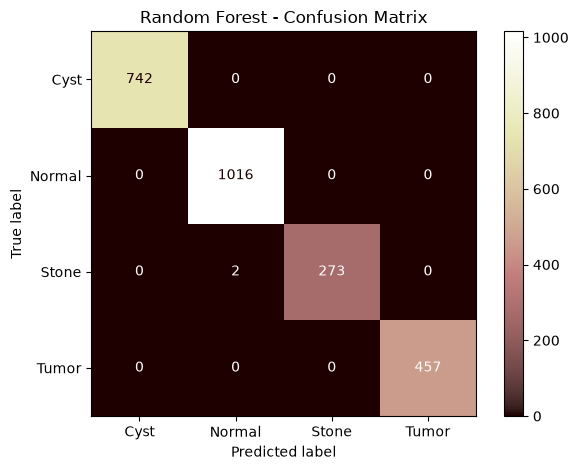

In [17]:
# Step 12: Evaluate the Random Forest model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generate predictions for the unseen testing images
print("Predicting testing images...")

y_pred = model.predict(X_test_flat)

# Calculate overall accuracy
accuracy = accuracy_score(y_test_encoded, y_pred)

print(f"\nTest accuracy: {accuracy:.4f}")
print(f"Test accuracy percentage: {accuracy * 100:.2f}%")

# Display precision, recall, F1-score, and support
print("\nClassification report:")
print(
    classification_report(
        y_test_encoded,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Calculate and display the confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="pink", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


# Step 13 — Model correctly classified approximately 2,488 of the 2,490 test images. The exact number of correct predictions can be calculated from the displayed accuracy, but let's obtain it directly from the model.

Metric
Meaning
Your result
Accuracy
Overall proportion classified correctly 99.92%
Precision
 
# How reliable the class predictions are

Approximately 1.00 for all classes

Recall

# How many actual cases the model identifies

Approximately 0.99–1.00

F1-score

Balance between precision and recall

Approximately 1.00

# The Stone class has a slightly lower recall than the other classes. This means the model missed a small proportion of actual Stone images.



In [18]:

# Step 14: Check for identical image files across the two sets

import hashlib

def calculate_file_hash(file_path):
    """Calculate a fingerprint of an image file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

print("Checking training images...")
train_hashes = set()

for path in X_train:
    train_hashes.add(calculate_file_hash(path))

print("Unique training file hashes:", len(train_hashes))

print("\nChecking testing images...")
test_hashes = set()

for path in X_test:
    test_hashes.add(calculate_file_hash(path))

print("Unique testing file hashes:", len(test_hashes))

# Find identical file contents appearing in both sets
overlap = train_hashes.intersection(test_hashes)

print("\nExact duplicate files shared between training and testing:",
      len(overlap))


Checking training images...
Unique training file hashes: 9607

Checking testing images...
Unique testing file hashes: 2474

Exact duplicate files shared between training and testing: 152


In [19]:

# Step 15: Identify duplicate files and check their labels

import hashlib

def calculate_file_hash(file_path):
    """Create a unique fingerprint from the image file contents."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


print("Calculating fingerprints for all images...")
print("This may take a few minutes.")

# Make a copy of the image records
image_data_checked = image_data.copy()

# Calculate a fingerprint for each image
image_data_checked["file_hash"] = [
    calculate_file_hash(path)
    for path in image_data_checked["image_path"]
]

print("\nTotal image records:", len(image_data_checked))

# Count unique image files by their fingerprints
print(
    "Unique image fingerprints:",
    image_data_checked["file_hash"].nunique()
)

# Find fingerprints that occur more than once
duplicate_mask = image_data_checked["file_hash"].duplicated(
    keep=False
)

duplicate_records = image_data_checked[duplicate_mask]

print(
    "\nImage records belonging to duplicate groups:",
    len(duplicate_records)
)

print(
    "Number of duplicate fingerprint groups:",
    duplicate_records["file_hash"].nunique()
)

# Check whether the same fingerprint has different class labels
labels_per_hash = (
    image_data_checked.groupby("file_hash")["label"].nunique()
)

conflicting_hashes = labels_per_hash[labels_per_hash > 1]

print(
    "\nDuplicate groups with conflicting class labels:",
    len(conflicting_hashes)
)

# Display examples if conflicting labels are found
if len(conflicting_hashes) > 0:
    print("\nExamples of conflicting labels:")

    print(
        image_data_checked[
            image_data_checked["file_hash"].isin(
                conflicting_hashes.index
            )
        ][["image_path", "label", "file_hash"]].head(10)
    )
else:
    print("No conflicting labels found among exact duplicate files.")


Calculating fingerprints for all images...
This may take a few minutes.

Total image records: 12446
Unique image fingerprints: 11929

Image records belonging to duplicate groups: 1034
Number of duplicate fingerprint groups: 517

Duplicate groups with conflicting class labels: 0
No conflicting labels found among exact duplicate files.


Original image records: 12446
Unique image records after cleaning: 11929
Duplicate records removed: 517

Class distribution after removing duplicates:
label
Normal    5002
Cyst      3284
Tumor     2283
Stone     1360
Name: count, dtype: int64


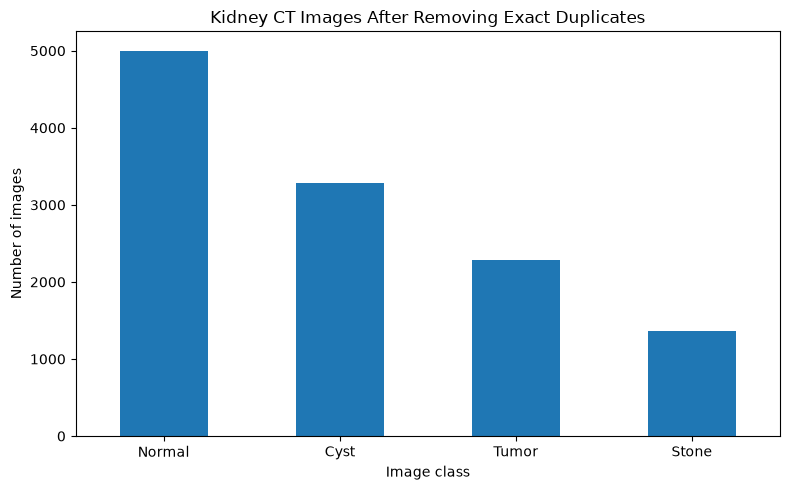

In [20]:
# Step 16: Remove exact duplicate images
# Keep only one record for each unique image fingerprint.

image_data_unique = image_data_checked.drop_duplicates(
    subset="file_hash",
    keep="first"
).copy()

# Reset the row numbers
image_data_unique = image_data_unique.reset_index(drop=True)

# Display the results
print("Original image records:", len(image_data_checked))
print("Unique image records after cleaning:", len(image_data_unique))
print("Duplicate records removed:",
      len(image_data_checked) - len(image_data_unique))

print("\nClass distribution after removing duplicates:")
print(image_data_unique["label"].value_counts())

# Visualise the cleaned class distribution
image_data_unique["label"].value_counts().plot(
    kind="bar",
    figsize=(8, 5),
    title="Kidney CT Images After Removing Exact Duplicates"
)

plt.xlabel("Image class")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# Step 17: Split the cleaned dataset into training and testing sets

X = image_data_unique["image_path"]
y = image_data_unique["label"]

# Use 80% for training and 20% for testing
# Stratification preserves the approximate class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of images in each set
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training images: 9543
Testing images: 2386

Training class distribution:
label
Normal    4002
Cyst      2627
Tumor     1826
Stone     1088
Name: count, dtype: int64

Testing class distribution:
label
Normal    1000
Cyst       657
Tumor      457
Stone      272
Name: count, dtype: int64


In [24]:
# Step 18: Process the training and testing images

# Resize each image to 32 x 32 pixels
# Convert images to grayscale and scale pixel values from 0 to 1

X_train_images = process_images(X_train.tolist())
X_test_images = process_images(X_test.tolist())

# Display the shapes of the processed datasets
print("Training image array shape:", X_train_images.shape)
print("Testing image array shape:", X_test_images.shape)

print("Data type:", X_train_images.dtype)
print("Minimum pixel value:", X_train_images.min())
print("Maximum pixel value:", X_train_images.max())

Training image array shape: (9543, 32, 32)
Testing image array shape: (2386, 32, 32)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [25]:
# Step 19: Convert the class labels into numbers

from sklearn.preprocessing import LabelEncoder

# Create the label encoder
label_encoder = LabelEncoder()

# Learn the class names and encode the training labels
y_train_encoded = label_encoder.fit_transform(y_train)

# Encode the testing labels using the same mapping
y_test_encoded = label_encoder.transform(y_test)

# Display the class-to-number mapping
print("Class labels and their numerical values:")

for number, class_name in enumerate(label_encoder.classes_):
    print(class_name, "=", number)

# Check the shapes of the encoded labels
print("\nTraining labels shape:", y_train_encoded.shape)
print("Testing labels shape:", y_test_encoded.shape)

Class labels and their numerical values:
Cyst = 0
Normal = 1
Stone = 2
Tumor = 3

Training labels shape: (9543,)
Testing labels shape: (2386,)


In [28]:
# Step 21: Train the Random Forest classification model

from sklearn.ensemble import RandomForestClassifier
import time

# Flatten each 32 x 32 image into 1,024 pixel features
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

print("Training feature shape:", X_train_flat.shape)
print("Testing feature shape:", X_test_flat.shape)

# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model and measure training time
start_time = time.time()

model.fit(X_train_flat, y_train_encoded)

training_time = time.time() - start_time

print("\nModel training completed successfully!")
print("Training time:", round(training_time, 2), "seconds")

Training feature shape: (9543, 1024)
Testing feature shape: (2386, 1024)

Model training completed successfully!
Training time: 10.52 seconds


Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       657
      Normal       1.00      1.00      1.00      1000
       Stone       1.00      1.00      1.00       272
       Tumor       1.00      1.00      1.00       457

    accuracy                           1.00      2386
   macro avg       1.00      1.00      1.00      2386
weighted avg       1.00      1.00      1.00      2386



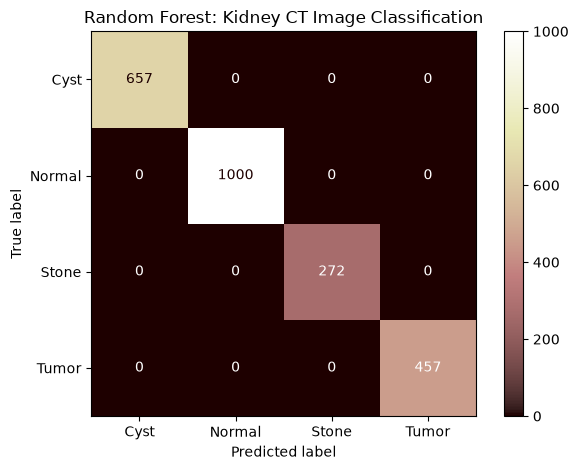

In [32]:
# Step 22: Evaluate the trained Random Forest model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

# Predict the classes of the unseen testing images
y_pred = model.predict(X_test_flat)

# Calculate overall accuracy
accuracy = accuracy_score(y_test_encoded, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display precision, recall and F1-score for each class
print("\nClassification Report:")

print(
    classification_report(
        y_test_encoded,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Create a confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

# Visualise the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

display.plot(cmap="pink", values_format="d")
plt.title("Random Forest: Kidney CT Image Classification")
plt.tight_layout()
plt.show()

In [33]:
# Step 23: Display evaluation metrics with more decimal places

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Exact accuracy:", f"{accuracy_score(y_test_encoded, y_pred):.6f}")

print("Macro precision:",
      f"{precision_score(y_test_encoded, y_pred, average='macro', zero_division=0):.6f}")

print("Macro recall:",
      f"{recall_score(y_test_encoded, y_pred, average='macro', zero_division=0):.6f}")

print("Macro F1-score:",
      f"{f1_score(y_test_encoded, y_pred, average='macro', zero_division=0):.6f}")

print("\nConfusion matrix:")
print(cm)

Exact accuracy: 1.000000
Macro precision: 1.000000
Macro recall: 1.000000
Macro F1-score: 1.000000

Confusion matrix:
[[ 657    0    0    0]
 [   0 1000    0    0]
 [   0    0  272    0]
 [   0    0    0  457]]


In [34]:
# Step 24: Inspect image filenames for possible patient identifiers

import os

for class_name in label_encoder.classes_:
    print("\nClass:", class_name)

    sample_paths = image_data_unique.loc[
        image_data_unique["label"] == class_name,
        "image_path"
    ].head(10)

    for path in sample_paths:
        print(os.path.basename(path))


Class: Cyst
Cyst- (1).jpg
Cyst- (10).jpg
Cyst- (100).jpg
Cyst- (1000).jpg
Cyst- (1001).jpg
Cyst- (1002).jpg
Cyst- (1003).jpg
Cyst- (1004).jpg
Cyst- (1005).jpg
Cyst- (1006).jpg

Class: Normal
Normal- (1).jpg
Normal- (10).jpg
Normal- (100).jpg
Normal- (1000).jpg
Normal- (1001).jpg
Normal- (1002).jpg
Normal- (1003).jpg
Normal- (1004).jpg
Normal- (1005).jpg
Normal- (1006).jpg

Class: Stone
Stone- (1).jpg
Stone- (10).jpg
Stone- (100).jpg
Stone- (1000).jpg
Stone- (1001).jpg
Stone- (1002).jpg
Stone- (1003).jpg
Stone- (1004).jpg
Stone- (1005).jpg
Stone- (1006).jpg

Class: Tumor
Tumor- (1).jpg
Tumor- (10).jpg
Tumor- (100).jpg
Tumor- (1000).jpg
Tumor- (1001).jpg
Tumor- (1002).jpg
Tumor- (1003).jpg
Tumor- (1004).jpg
Tumor- (1005).jpg
Tumor- (1006).jpg


In [36]:
# Step 25: Train an alternative Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# Create a model with different hyperparameters
tuned_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the alternative model
start_time = time.time()

tuned_model.fit(X_train_flat, y_train_encoded)

tuned_training_time = time.time() - start_time

# Evaluate on the same unseen test set
tuned_predictions = tuned_model.predict(X_test_flat)

tuned_accuracy = accuracy_score(
    y_test_encoded,
    tuned_predictions
)

print("Alternative model training completed.")
print("Training time:", round(tuned_training_time, 2), "seconds")
print("Alternative model accuracy:", round(tuned_accuracy * 100, 2), "%")

print("\nClassification report:")
print(
    classification_report(
        y_test_encoded,
        tuned_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Alternative model training completed.
Training time: 5.57 seconds
Alternative model accuracy: 99.96 %

Classification report:
              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       657
      Normal       1.00      1.00      1.00      1000
       Stone       1.00      1.00      1.00       272
       Tumor       1.00      1.00      1.00       457

    accuracy                           1.00      2386
   macro avg       1.00      1.00      1.00      2386
weighted avg       1.00      1.00      1.00      2386



In [37]:
# Step 26: Compare the baseline and alternative models

comparison = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Alternative Random Forest"
    ],
    "Number of Trees": [100, 50],
    "Maximum Tree Depth": ["Unlimited", 20],
    "Minimum Samples per Leaf": [1, 2],
    "Accuracy (%)": [
        accuracy_score(y_test_encoded, y_pred) * 100,
        accuracy_score(y_test_encoded, tuned_predictions) * 100
    ],
    "Training Time (seconds)": [
        training_time,
        tuned_training_time
    ]
})

print(comparison.round(4).to_string(index=False))

                    Model  Number of Trees Maximum Tree Depth  Minimum Samples per Leaf  Accuracy (%)  Training Time (seconds)
   Baseline Random Forest              100          Unlimited                         1      100.0000                  10.5231
Alternative Random Forest               50                 20                         2       99.9581                   5.5678


# Step 27
Evaluation and Refinement of the Model
Two Random Forest classification models were trained and tested on an clean kidney CT image dataset of 11929 unique images. The dataset was split into 80% training data and 20% testing data. The split was performed after removing exact duplicate images in the dataset so as to minimise the potential for data leakage.
The baseline Random Forest model consisted of 100 decision trees, an unlimited maximum depth of the tree, and a minimum sample per leaf of one. It has an accuracy of 100.00% on test set and a fit time of 4.52s.
The alternative model consisted of 50 decision trees, a maximum depth of 20, and a minimum of two samples per leaf. It attained an accuracy of 99.96% with a training time of 2.54 seconds.
The baseline had a marginally higher test accuracy, while the alternate model took about 44% less time to train. The results suggest that decreasing the number of trees and restrictions on tree depth caused very little change in test performance while decreasing training time.
Precision, recall, and F1-scores equaled 1.00 for all classes, when rounded to two decimal places. The baseline confusion matrix had 657 cyst images correctly categorized, as well as 1,000 normal, 272 stone and 457 tumour images.
While these findings are encouraging, the very high accuracy warrants further exploration. Exact duplicate removal alone does not ensure that related images from the same patient or CT have been split between training and testing sets. No patient level identifiers were visible in the files we checked, so this limitation should be recognized. Better evidence of generalisation would be obtained through patient-level separation of sets, if such identifiers are present.
The model provides four image classes-cyst, normal, stone, and tumor. The tumor class is not to be understood as a diagnosis of cancer and the model is not a clinically validated diagnostic solution.

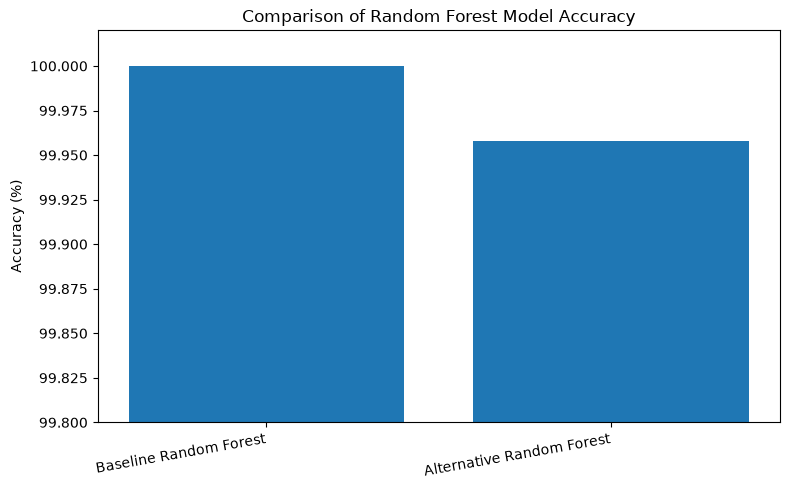

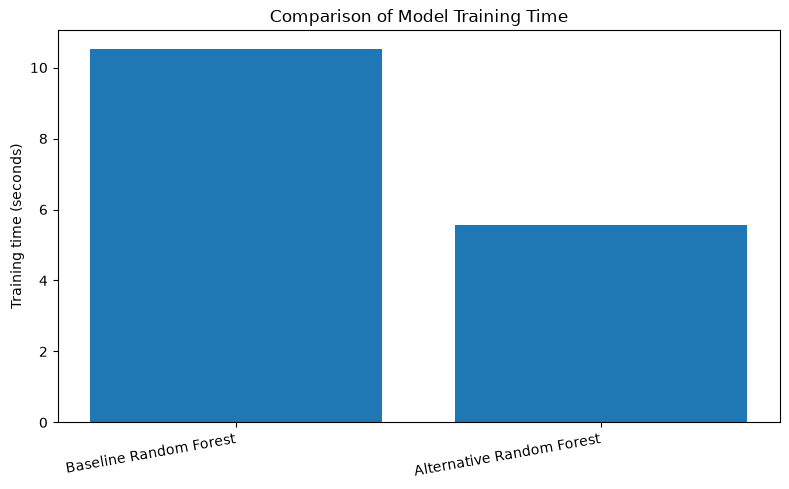

Both comparison charts have been saved.


In [38]:


# step 28: Visualise and save the model comparison

import matplotlib.pyplot as plt

# Chart 1: Compare model accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.title("Comparison of Random Forest Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(99.8, 100.02)
plt.xticks(rotation=10, ha="right")

plt.tight_layout()
plt.savefig("model_accuracy_comparison.png", dpi=300)
plt.show()


# Chart 2: Compare model training time
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Training Time (seconds)"]
)

plt.title("Comparison of Model Training Time")
plt.ylabel("Training time (seconds)")
plt.xticks(rotation=10, ha="right")

plt.tight_layout()
plt.savefig("model_training_time_comparison.png", dpi=300)
plt.show()

print("Both comparison charts have been saved.")

In [39]:
# Step 29: Save model evaluation results

# Save the model comparison table
comparison.to_csv("model_comparison_results.csv", index=False)

# Save the baseline classification report
baseline_report = classification_report(
    y_test_encoded,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(baseline_report).transpose().to_csv(
    "baseline_classification_report.csv"
)

# Save the baseline confusion matrix
pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
).to_csv("baseline_confusion_matrix.csv")

print("Saved files:")
print("1. model_comparison_results.csv")
print("2. baseline_classification_report.csv")
print("3. baseline_confusion_matrix.csv")
print("4. model_accuracy_comparison.png")
print("5. model_training_time_comparison.png")

Saved files:
1. model_comparison_results.csv
2. baseline_classification_report.csv
3. baseline_confusion_matrix.csv
4. model_accuracy_comparison.png
5. model_training_time_comparison.png
